In [ ]:
!pip install emoji

In [ ]:
#những thư viện cơ bản
import numpy as np
import nltk
import pandas as pd
import matplotlib.pyplot as plt
import re
#những cái cần để lấy file từ drive
from google.colab import drive
import os

#kiểm tra emoji
import emoji

#những thư viện liên quan đến scikit learn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

In [ ]:
nltk.download('stopwords')
nltk.download('punkt')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [ ]:
train_pq = pd.read_parquet('train-00000-of-00001-daf190ce720b3dbb.parquet')
test_pq= pd.read_parquet('test-00000-of-00001-fa9b3e8ade89a333.parquet')
e_sms = pd.read_csv('email.csv').drop_duplicates()
spam_ham = pd.read_csv('spam_ham_dataset.csv').drop(columns=['Unnamed: 0']).drop_duplicates()



In [ ]:

# Khởi tạo bộ Stemmer để chuẩn hóa từ về dạng gốc
stemmer = nltk.stem.PorterStemmer()

def is_emoji(text):
    for char in text:
        if emoji.is_emoji(char):
            return True
    return False

def clean_emoji(text):
    for char in text:
        if emoji.is_emoji(char):
            text = text.replace(char, 'EMOJI')
    return text

def clean_url(text):
    urls = re.findall(r'http[s]?://(?:[a-zA-Z]|[0-9]|[$-_@.&+]|[!*\\(\\),]|(?:%[0-9a-fA-F][0-9a-fA-F]))+', text)
    for url in urls:
        text = text.replace(url, 'URL')
    return text

def clean_html(text):
    html_tags = re.findall(r'<[^>]+>', text)
    for tag in html_tags:
        text = text.replace(tag, 'HTML')
    return text

def clean_number(text):
    numbers = re.findall(r'\d+', text)
    for number in numbers:
        text = text.replace(number, 'NUMBER')
    return text

def clean_email_address(text):
    email_addresses = re.findall(r'[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}',text)
    for email in email_addresses:
        text = text.replace(email, 'EMAIL')
    return text

def clean_special_characters(text):
    # Giữ chữ cái, khoảng trắng và dấu nháy trong từ
    text = re.sub(r"[^a-zA-Z\s']", ' ', text)
    return text

def normalize_word(text):
    tmp = text.split()
    return ' '.join(stemmer.stem(word) for word in tmp)

def remove_stopwords(text):
    stop_words = set(nltk.corpus.stopwords.words('english'))
    tmp = text.split()
    return ' '.join(word for word in tmp if word not in stop_words)

def clean_text(text):
    text = clean_emoji(text)
    text = clean_url(text)
    text = clean_html(text)
    text = clean_number(text)
    text = clean_email_address(text)
    text = text.lower()
    text = normalize_word(text)
    text = remove_stopwords(text)
    text = clean_special_characters(text)
    return text

def label_to_num(text):
    return 1 if text == 'spam' else 0

test_text = train_pq['text'][12]
print("Văn bản gốc:")
print(test_text)
print("\nVăn bản sau khi làm sạch:")
print(clean_text(test_text))

Văn bản gốc:
HEY EVERYONE!!! 👋👋👋

Are you Tired 😴 of boring 😒 posts?? Me too!!! That's why I'm here to spice things up on this app 🌶️🌶️🌶️!!!

Are you looking for a way to lose weight 💪🏃‍♀️🥦 and gain muscle 💪💪💪? Do not worry, I have the solution for you!!! 🙌🙌🙌

Introducing the amazing 🤩🤩🤩 diet pills that will make you lose weight in

Văn bản sau khi làm sạch:
hey everyone    emojiemojiemoji tire emoji bore emoji posts   too    that' whi spice thing thi app emoji emoji emoji     look way lose weight emojiemoji emoji emoji gain muscl emojiemojiemoji  worry  solut you    emojiemojiemoji introduc amaz emojiemojiemoji diet pill make lose weight


Tiền sử lý đầu vào, ta loại bỏ hậu tố sử dụng stemming (có thể sử dụng lemmatiztion nhưng tôi sẽ ưu tiên tốc độ hơn), loại bỏ những stop word, đánh dấu những khoảng có số, emoji hoặc những điểm đặc biệt. đưa về plain text để chuẩn bị TF-IDF

In [160]:
import numpy as np
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import GroupShuffleSplit

# robust label mapping: handles 'spam'/'ham' strings and 0/1 integers
def to_num(x):
    return 1 if str(x).strip().lower() in ('spam', '1') else 0

# 1. one pool with a source column (no splitting yet)
sms = (e_sms[e_sms['Category'].isin(['ham', 'spam'])]
       .rename(columns={'Message': 'text', 'Category': 'label'}))
sms['source'] = 'sms'

enron = spam_ham.drop(columns=['label']).rename(columns={'label_num': 'label'})
enron['source'] = 'enron'

pq1 = train_pq[['text', 'label']].copy(); pq1['source'] = 'pq'
pq2 = test_pq[['text', 'label']].copy();  pq2['source'] = 'pq'

all_df = pd.concat([d[['text', 'label', 'source']] for d in (sms, enron, pq1, pq2)],
                   ignore_index=True)
all_df = all_df.dropna(subset=['text'])
all_df['label'] = all_df['label'].map(to_num)

# 2. clean, then dedupe on the CLEANED text
all_df['text'] = all_df['text'].apply(clean_text)
all_df = all_df[all_df['text'].str.strip() != ''].drop_duplicates('text').reset_index(drop=True)

# 3. cluster near-duplicates (cosine >= 0.9), in chunks to save memory
X = TfidfVectorizer(min_df=2, max_df=0.5).fit_transform(all_df['text'])
rows, cols = [], []
for i in range(0, X.shape[0], 2000):
    sim = (X[i:i+2000] @ X.T).toarray()
    r, c = np.where(sim >= 0.9)
    rows.append(r + i); cols.append(c)
rows, cols = np.concatenate(rows), np.concatenate(cols)
graph = coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(X.shape[0],) * 2)
_, groups = connected_components(graph, directed=False)

# 4. split so each cluster stays on one side
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_idx, te_idx = next(gss.split(all_df, groups=groups))
train, test = all_df.iloc[tr_idx].copy(), all_df.iloc[te_idx].copy()

print(train['label'].value_counts(), test['label'].value_counts())
print(all_df.groupby('source')['label'].agg(['count', 'mean']))   # spam ratio per source

label
0    10345
1     6072
Name: count, dtype: int64 label
0    2553
1    1504
Name: count, dtype: int64
        count      mean
source                 
enron    4710  0.309979
pq      10640  0.516823
sms      5124  0.120414


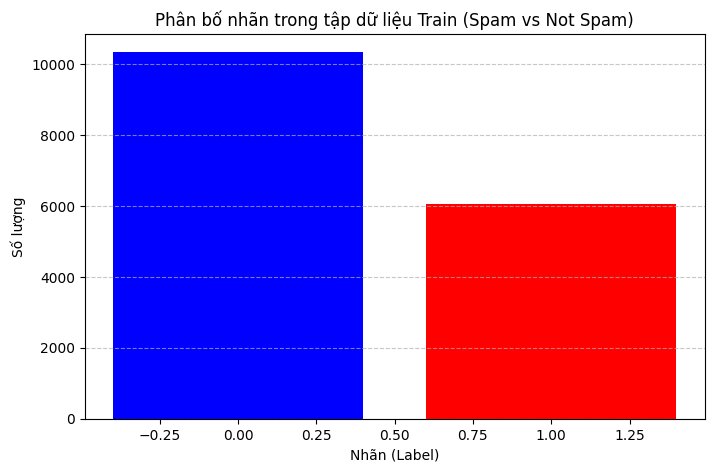

label
0    10345
1     6072
Name: count, dtype: int64


In [161]:
# Đếm số lượng của từng nhãn (spam vs not_spam)
label_counts = train['label'].value_counts()

# Vẽ biểu đồ cột trực quan hóa
plt.figure(figsize=(8, 5))
plt.bar(label_counts.index, label_counts.values, color=['blue', 'red'])
plt.title('Phân bố nhãn trong tập dữ liệu Train (Spam vs Not Spam)')
plt.xlabel('Nhãn (Label)')
plt.ylabel('Số lượng')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

print(label_counts)

In [164]:
train = train.dropna()
text = train['text']
label = train['label']

In [165]:
tdf_word = TfidfVectorizer(
    lowercase=False,
    ngram_range=(1, 2),
    max_features=20000,
    min_df=3,
    max_df=0.95,
    sublinear_tf=True,
)
tdf_pharse = TfidfVectorizer(
    lowercase=False,
    analyzer='char_wb',
    ngram_range=(2,5),
    max_features=20000,
    min_df=3,
    max_df=0.95,
    sublinear_tf=True,
)

x_word = tdf_word.fit_transform(text)
x_pharse = tdf_pharse.fit_transform(text)

x_word.shape, x_pharse.shape

((16417, 20000), (16417, 20000))

In [166]:
model_word = LogisticRegression(max_iter=1000, class_weight='balanced')
model_pharse = LogisticRegression(max_iter=1000, class_weight='balanced')

model_word.fit(x_word, label)
model_pharse.fit(x_pharse, label)



LogisticRegression(class_weight='balanced', max_iter=1000)

In [167]:
test = test.dropna()
test_word = tdf_word.transform(test['text'])
test_pharse = tdf_pharse.transform(test['text'])
test_ans = test['label']

In [168]:
for m in (model_pharse, model_word):
    pred = m.predict(test_word if m == model_word else test_pharse)
    print('word' if m == model_word else 'pharse')
    print(accuracy_score(test_ans, pred))
    print(classification_report(test_ans, pred))
    print(confusion_matrix(test_ans, pred))
#

pharse
0.9795415331525757
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      2553
           1       0.98      0.97      0.97      1504

    accuracy                           0.98      4057
   macro avg       0.98      0.98      0.98      4057
weighted avg       0.98      0.98      0.98      4057

[[2521   32]
 [  51 1453]]
word
0.9790485580478185
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      2553
           1       0.98      0.96      0.97      1504

    accuracy                           0.98      4057
   macro avg       0.98      0.98      0.98      4057
weighted avg       0.98      0.98      0.98      4057

[[2529   24]
 [  61 1443]]


In [172]:
for src, g in test.groupby('source'):
    print('==', src, len(g))
    for name, m, vec in (('word', model_word, tdf_word), ('char', model_pharse, tdf_pharse)):
        pred = m.predict(vec.transform(g['text']))
        print(name, round(accuracy_score(g['label'], pred), 4))
        print(confusion_matrix(g['label'], pred))

== enron 920
word 0.9467
[[598  15]
 [ 34 273]]
char 0.9587
[[590  23]
 [ 15 292]]
== pq 2105
word 0.9943
[[1032    2]
 [  10 1061]]
char 0.9919
[[1027    7]
 [  10 1061]]
== sms 1032
word 0.9767
[[899   7]
 [ 17 109]]
char 0.9729
[[904   2]
 [ 26 100]]


In [177]:
super_test = '''
From: People’s Bank [service@peoples.com]
Subject: Update Notifi cation
 Dear People’s Bank® Customer,
Recently there have been a large number of identity theft attempts targeting our customers. In order to safeguard
your account, we require that you confi rm your banking details.
This process is mandatory, and if not completed within the nearest time your account or credit card may be
subject to temporary suspension.
To securely confi rm your People’s Bank Account details please follow the link:
LINK REMOVED FROM THIS EXAMPLE.
Note: You may have to report this message as “Not Junk Mail” if update link does not work.
Thank you for your prompt attention to this matter and thank you for using People’s Bank.
© Copyright 2005, People’s Bank, Inc. All Rights Reserved
'''

print(model_pharse.predict_proba(tdf_pharse.transform([super_test])))
print(model_word.predict_proba(tdf_word.transform([super_test])))


[[0.26301479 0.73698521]]
[[0.54125908 0.45874092]]
